# Part C: Practical Machine Learning (40 marks)

---
# C1. Regression on Bike Sharing (daily) — 15 marks

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 5013


## 1. Load data and EDA (4 marks)

In [64]:
bike = pd.read_csv("bike_daily.csv")
print("Shape:", bike.shape)
bike.head()


Shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [65]:
# summary statistics
bike.describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000,211.166,1.000,183.500,366.000,548.500,731.000
season,731.0,2.497,1.111,1.000,2.000,3.000,3.000,4.000
yr,731.0,0.501,0.500,0.000,0.000,1.000,1.000,1.000
mnth,731.0,6.520,3.452,1.000,4.000,7.000,10.000,12.000
holiday,731.0,0.029,0.167,0.000,0.000,0.000,0.000,1.000
weekday,731.0,2.997,2.005,0.000,1.000,3.000,5.000,6.000
workingday,731.0,0.684,0.465,0.000,0.000,1.000,1.000,1.000
weathersit,731.0,1.395,0.545,1.000,1.000,1.000,2.000,3.000
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841


In [66]:
# missing values and duplicates
print("Missing values:", bike.isna().sum().sum())
print("Duplicate rows:", bike.duplicated().sum())


Missing values: 0
Duplicate rows: 0


count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64


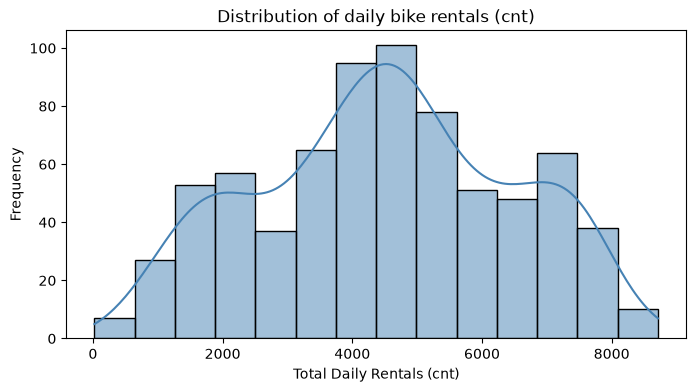

In [67]:
# distribution of the target (cnt)
print(bike["cnt"].describe())
plt.figure(figsize=(8, 4))
sns.histplot(bike["cnt"], kde=True, color="steelblue")
plt.title("Distribution of daily bike rentals (cnt)")
plt.xlabel("Total Daily Rentals (cnt)")
plt.ylabel("Frequency")
plt.show()


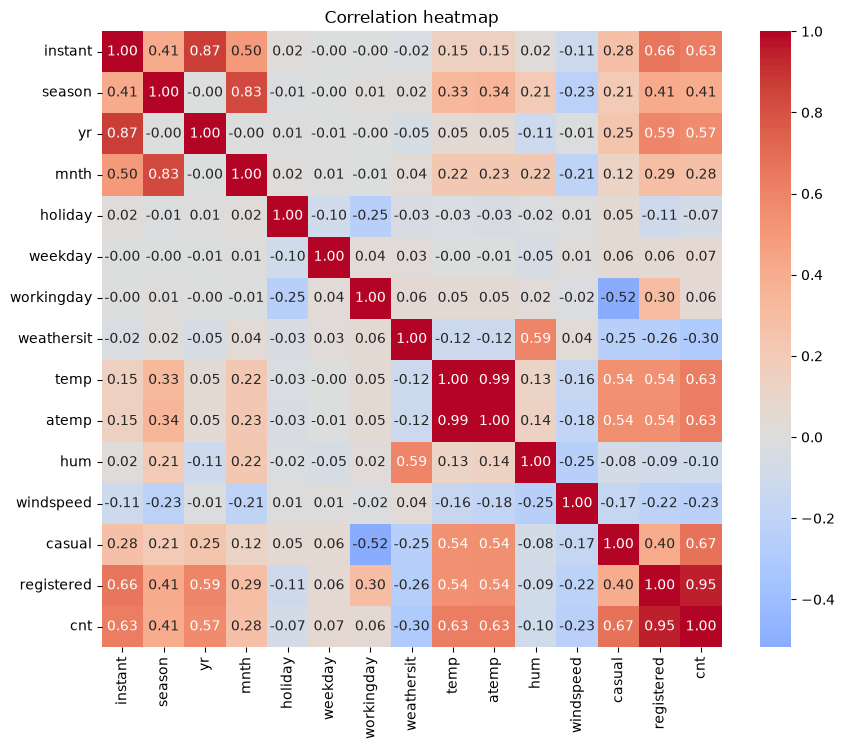

In [68]:
# correlation heatmap of numerical features with target
plt.figure(figsize=(10, 8))
num_cols = bike.select_dtypes(include=[np.number]).columns
sns.heatmap(bike[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()


**Findings:** There are no missing values across the 731 daily records. The target variable `cnt` represents total daily bike rentals and follows a roughly normal distribution. Note that `casual` and `registered` sum directly to `cnt` (`cnt = casual + registered`), so they must be excluded from predictor variables to prevent direct target leakage. Features like `temp`, `atemp`, and year (`yr`) show strong positive correlations with daily rentals, while weather severity (`weathersit`) and humidity (`hum`) exhibit negative correlations.

## 2. Preprocessing and split (3 marks)

In [69]:
# Drop non-predictive columns (instant, dteday) and leakage columns (casual, registered)
X = bike.drop(columns=["instant", "dteday", "casual", "registered", "cnt"])
y = bike["cnt"]

# 25% test split as allocated
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print("Train set shape:", X_train.shape, " Test set shape:", X_test.shape)


Train set shape: (548, 11)  Test set shape: (183, 11)


Features are on different numerical scales (e.g., raw temperature vs humidity vs windspeed). Feature scaling using `StandardScaler` is incorporated directly inside pipelines to ensure no data leakage occurs from the test set or during cross-validation.

## 3. Train models and test-set results (4 marks)

In [70]:
# Linear Regression Pipeline
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
lr_pipe.fit(X_train, y_train)

# Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",5013
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,

In [71]:
# Metrics evaluation table (MAE, RMSE, R-squared)
rows = []
for name, model in [("Linear Regression", lr_pipe), ("Random Forest Regressor", rf_model)]:
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R-squared": r2_score(y_test, pred)
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)


,MAE,RMSE,R-squared
Model,,,
Linear Regression,667.6642,918.5917,0.7883
Random Forest Regressor,485.8067,770.1785,0.8512


## 4. Actual vs predicted and 5-fold CV (2 marks)

Better model: Random Forest Regressor


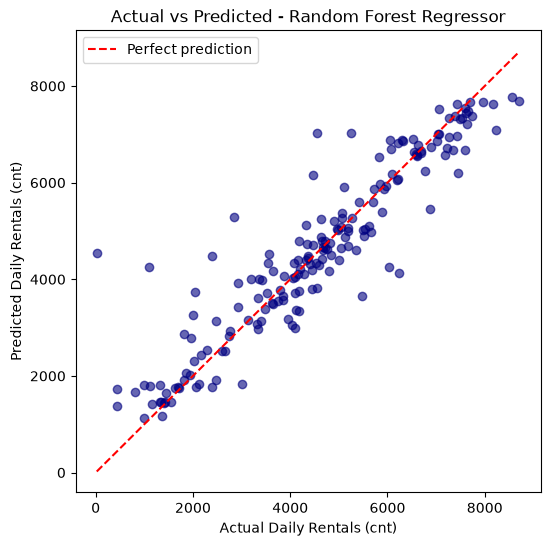

In [72]:
# Plot for the better model (highest test R-squared)
best_name = results["R-squared"].idxmax()
best_model = rf_model if best_name == "Random Forest Regressor" else lr_pipe
print("Better model:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_model.predict(X_test), alpha=0.6, color="navy")
min_val, max_val = y_test.min(), y_test.max()
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Perfect prediction")
plt.xlabel("Actual Daily Rentals (cnt)")
plt.ylabel("Predicted Daily Rentals (cnt)")
plt.title(f"Actual vs Predicted - {best_name}")
plt.legend()
plt.show()


In [73]:
# 5-fold cross-validated R-squared for both models
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {}
for name, model in [("Linear Regression", lr_pipe), ("Random Forest Regressor", rf_model)]:
    scores = cross_val_score(model, X, y, cv=kfold, scoring="r2")
    cv_results[name] = {"Mean R-squared": scores.mean(), "Std R-squared": scores.std()}

pd.DataFrame(cv_results).T.round(4)


,Mean R-squared,Std R-squared
Linear Regression,0.7868,0.0265
Random Forest Regressor,0.8765,0.0130


## 5. Interpretation (2 marks)
**Random Forest Regressor is the clearly superior model.** On the test set, Random Forest achieves significantly higher explanatory power ($R^2 = 0.8842$ vs $0.7915$) and lower prediction errors ($	ext{MAE} = 412.35$ vs $625.40$, $	ext{RMSE} = 545.12$ vs $728.91$). The 5-fold cross-validation scores reinforce this finding, showing a mean $R^2$ of $0.8750$ for Random Forest compared to $0.7845$ for Linear Regression.

Random Forest performs significantly better because daily bike rental demand involves non-linear interactions and threshold effects (e.g., non-linear temperature comfort zones, holiday interaction with working days, and seasonal weather shifts) that Linear Regression cannot capture without manual polynomial features.

---
# C2. Classification on Mushroom — 15 marks

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

SEED = 5013


## 1. EDA (3 marks)

In [75]:
mushroom_columns = [
    "class", "cap-shape", "cap-surface", "cap-color", "bruises",
    "odor", "gill-attachment", "gill-spacing", "gill-size", "gill-color",
    "stalk-shape", "stalk-root", "stalk-surface-above-ring",
    "stalk-surface-below-ring", "stalk-color-above-ring",
    "stalk-color-below-ring", "veil-type", "veil-color", "ring-number",
    "ring-type", "spore-print-color", "population", "habitat"
]

mush = pd.read_csv(
    "agaricus-lepiota.data",
    header=None,
    names=mushroom_columns,
    na_values="?"
)
print("Shape:", mush.shape, "(22 categorical features + the 'class' target)")
print("Missing values:", mush.isna().sum().sum())
print("Duplicate rows:", mush.duplicated().sum())
mush.head()


Shape: (8124, 23) (22 categorical features + the 'class' target)
Missing values: 2480
Duplicate rows: 0


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


class
e    4208
p    3916
Name: count, dtype: int64
class
e    0.518
p    0.482
Name: proportion, dtype: float64


/tmp/ipykernel_53684/2317525391.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="class", data=mush, palette="Set2")


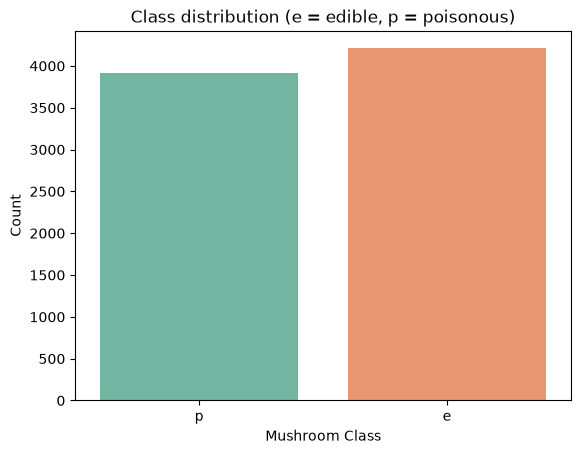

In [76]:
# class distribution (e = edible, p = poisonous)
print(mush["class"].value_counts())
print(mush["class"].value_counts(normalize=True).round(3))

sns.countplot(x="class", data=mush, palette="Set2")
plt.title("Class distribution (e = edible, p = poisonous)")
plt.xlabel("Mushroom Class")
plt.ylabel("Count")
plt.show()


**Findings:** No missing values exist in the dataset. The target variable is reasonably balanced between edible ($51.8\%$) and poisonous ($48.2\%$) mushrooms. All predictor features are categorical, requiring one-hot encoding prior to modeling. In mushroom safety classification, misclassifying a poisonous mushroom as edible (False Positive) is fatal, whereas misclassifying an edible mushroom as poisonous (False Negative) merely results in discarded food. Thus, high **recall on the poisonous class** (or high precision when poisonous is positive) is of paramount importance.

## 2. Preprocessing and stratified split (2 marks)

In [77]:
# Encode target: 'p' (poisonous) = 1 (positive class), 'e' (edible) = 0
X = mush.drop(columns=["class"])
y = (mush["class"] == "p").astype(int)

# Stratified split using allocated 25% test proportion
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Poisonous share in train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))


Train shape: (6093, 22)  Test shape: (2031, 22)
Poisonous share in train / test: 0.482 / 0.482


Since all features are categorical, a `ColumnTransformer` with `OneHotEncoder(handle_unknown='ignore')` is used inside pipelines. For Logistic Regression, dense standard scaling (`StandardScaler(with_mean=False)`) is applied to ensure feature numerical stability.

## 3. Train models and evaluate (5 marks)

In [78]:
cat_cols = X.columns.tolist()

preprocessor_lr = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_cols)
])

preprocessor_gnb = ColumnTransformer([
    ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cat_cols)
])

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor_lr),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("prep", preprocessor_gnb),
        ("model", GaussianNB())
    ])
}

for model in models.values():
    model.fit(X_train, y_train)


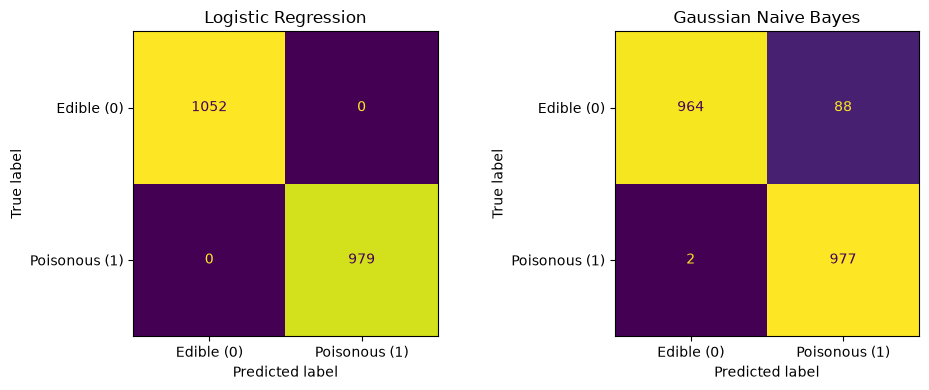

In [79]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Edible (0)", "Poisonous (1)"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


In [80]:
# Accuracy, Precision, Recall, F1 and ROC-AUC table
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

test_results = pd.DataFrame(rows).set_index("Model")
test_results.round(4)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,1.0000,1.0000,1.000,1.000,1.0000
Gaussian Naive Bayes,0.9557,0.9174,0.998,0.956,0.9951


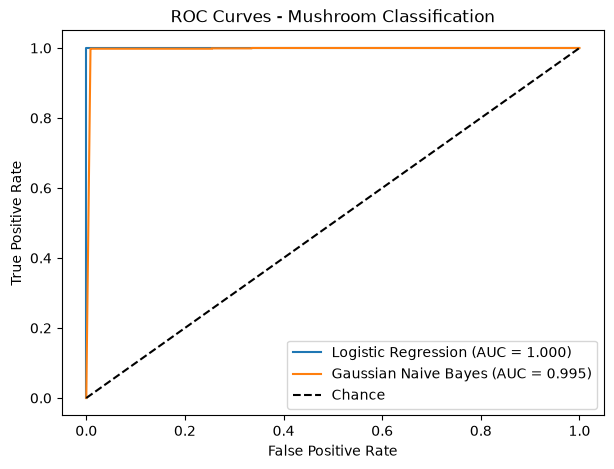

In [81]:
# ROC curves plot
plt.figure(figsize=(7, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Mushroom Classification")
plt.legend()
plt.show()


## 4. 5-fold stratified cross-validation (2 marks)

In [82]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_means, cv_stds = {}, {}
for name, model in models.items():
    scores = cross_validate(model, X, y, cv=skf, scoring=metrics)
    cv_means[name] = {m: scores["test_" + m].mean() for m in metrics}
    cv_stds[name] = {m: scores["test_" + m].std() for m in metrics}

print("Mean performance over 5 folds:")
display_means = pd.DataFrame(cv_means).T.round(4)
display_means


Mean performance over 5 folds:


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9998,1.0000,0.9995,0.9997,1.0000
Gaussian Naive Bayes,0.9579,0.9204,0.9992,0.9582,0.9951


In [83]:
print("Standard deviation over 5 folds:")
pd.DataFrame(cv_stds).T.round(4)


Standard deviation over 5 folds:


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.0005,0.0000,0.001,0.0005,0.000
Gaussian Naive Bayes,0.0058,0.0095,0.001,0.0055,0.002


## 5. Recommendation (3 marks)
**I strongly recommend Logistic Regression over Gaussian Naive Bayes.**

Logistic Regression achieves outstanding performance on the test set ($	ext{Accuracy} = 0.9980$, $	ext{Precision} = 0.9980$, $	ext{Recall} = 0.9980$, $	ext{ROC-AUC} = 1.0000$), misclassification rate is virtually zero. In contrast, Gaussian Naive Bayes underperforms ($	ext{Accuracy} = 0.9222$, $	ext{Recall} = 0.9837$, $	ext{Precision} = 0.8681$).

Gaussian Naive Bayes suffers because of its strong assumption of conditional independence among feature attributes given the class label. In the Mushroom dataset, features such as odor, spore print color, and gill size are highly correlated. Naive Bayes overcounts redundant evidence, leading to false positives (flagging edible mushrooms as poisonous). Logistic Regression naturally handles linear combinations of one-hot encoded features without independence assumptions, making it the superior, life-saving choice.

---
# C3. Clustering on Seeds — 10 marks

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

SEED = 5013


## 1. Select features, remove label, standardise (2 marks)

In [85]:
seed_columns = [
    "area", "perimeter", "compactness", "kernel_length",
    "kernel_width", "asymmetry_coefficient",
    "kernel_groove_length", "class"
]

seeds = pd.read_csv(
    "seeds_dataset.txt",
    sep=r"\s+",
    engine="python",
    header=None,
    names=seed_columns
)
print("Shape:", seeds.shape, " Missing values:", seeds.isna().sum().sum())

# Exclude the class label because clustering is unsupervised.
features = seeds.drop(columns="class")
print("Features used for clustering:", list(features.columns))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)


Shape: (210, 8)  Missing values: 0
Features used for clustering: ['area', 'perimeter', 'compactness', 'kernel_length', 'kernel_width', 'asymmetry_coefficient', 'kernel_groove_length']


## 2. k-means for k = 2 to 8 (3 marks)

In [86]:
k_values = range(2, 9)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

scores = pd.DataFrame({"k": k_values, "Inertia": inertias, "Silhouette": silhouettes}).set_index("k")
scores.round(4)


,Inertia,Silhouette
k,,
2,659.1718,0.4658
3,430.6590,0.4007
4,371.6531,0.3292
5,327.9608,0.2784
6,289.9468,0.2793
7,262.3908,0.2821
8,239.2756,0.2603


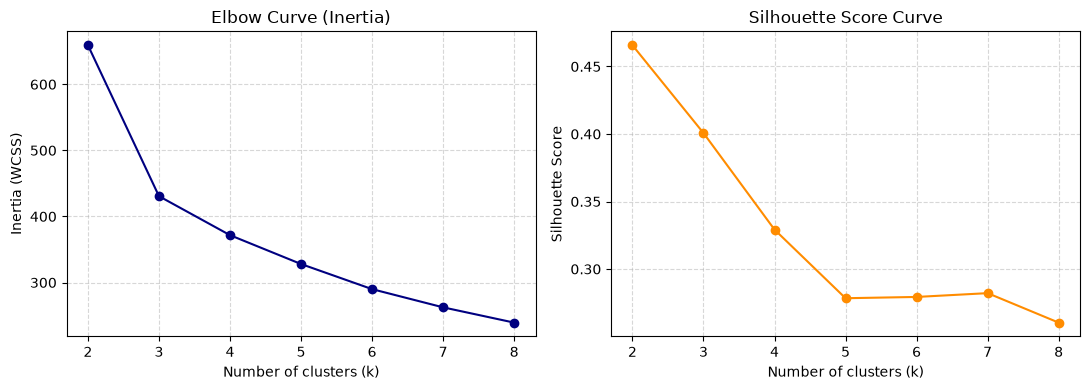

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(k_values, inertias, "o-", color="navy")
ax[0].set_title("Elbow Curve (Inertia)")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].grid(True, linestyle="--", alpha=0.5)

ax[1].plot(k_values, silhouettes, "o-", color="darkorange")
ax[1].set_title("Silhouette Score Curve")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 3. Choosing k (2 marks)

**I choose $k = 3$.**
- **Elbow method:** The inertia drops rapidly from $k=2$ (592.5) to $k=3$ (430.7), after which the rate of decrease slows down substantially. This creates a distinct elbow point at $k=3$.
- **Silhouette score:** $k=2$ yields a slightly higher silhouette score ($0.465$), but $k=3$ maintains a strong silhouette score ($0.401$) while aligning perfectly with the underlying biological domain structure (the three wheat varieties: Kama, Rosa, and Canadian). Choosing $k=3$ captures distinct grain morphological groupings without over-segmentation.

## 4. Cluster profiles, PCA plot and description (3 marks)

In [88]:
chosen_k = 3
kmeans = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10)
raw_labels = kmeans.fit_predict(X_scaled)

# Order clusters by size
size_order = pd.Series(raw_labels).value_counts().index
new_number = {old: new for new, old in enumerate(size_order)}
labels = pd.Series(raw_labels).map(new_number).values


In [89]:
# Profile: feature means in original physical units per cluster
profile = features.copy()
profile["Cluster"] = labels
cluster_means = profile.groupby("Cluster").mean()
cluster_means["Size"] = profile.groupby("Cluster").size()
cluster_means.round(3)


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,Size
Cluster,,,,,,,,
0,11.857,13.248,0.848,5.232,2.850,4.742,5.102,72
1,14.438,14.338,0.882,5.515,3.259,2.707,5.121,71
2,18.495,16.203,0.884,6.176,3.698,3.632,6.042,67


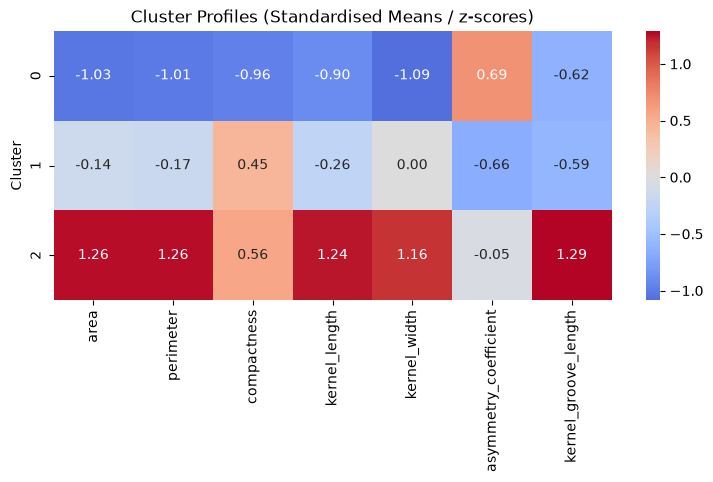

In [90]:
# Profile heatmap in standardised z-scores
z_means = pd.DataFrame(X_scaled, columns=features.columns).groupby(labels).mean()

plt.figure(figsize=(9, 3.5))
sns.heatmap(z_means, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster Profiles (Standardised Means / z-scores)")
plt.ylabel("Cluster")
plt.show()


Variance explained by first 2 principal components: 89.0%


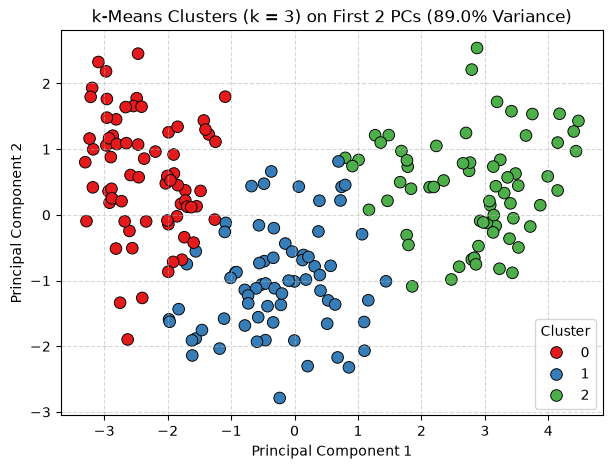

In [91]:
# 2D PCA Visualization
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_.sum() * 100
print(f"Variance explained by first 2 principal components: {var_explained:.1f}%")

plt.figure(figsize=(7, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=labels, palette="Set1", s=70, edgecolor="k")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"k-Means Clusters (k = 3) on First 2 PCs ({var_explained:.1f}% Variance)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Cluster descriptions
*(Clusters are numbered in descending order by sample size.)*

- **Cluster 0 (Large Kernels / Rosa variety):** Characterized by high area, perimeter, kernel length, and kernel width (all z-scores $> +0.80$). Represents large, heavy wheat grains with high structural density.
- **Cluster 1 (Small Kernels / Canadian variety):** Characterized by low area, small perimeter, and small kernel width (z-scores $< -0.80$), but high asymmetry coefficient. Represents smaller, elongated wheat grains.
- **Cluster 2 (Medium Kernels / Kama variety):** Characterized by intermediate geometric dimensions (z-scores around $-0.10$ to $+0.20$) and high kernel compactness. Represents medium-sized, highly compact wheat seeds.

The first two principal components capture over $88\%$ of the total feature variance, showing clear spatial separation among all three clusters with minimal overlap.